In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from matplotlib import pyplot as plt

In [2]:
df = pd.read_csv("Cartoon_datasets.csv")
df.head()

,Name,Span,Description,Rating
0,Batman: The Animated Series,(1992–1995),The Dark Knight battles crime in Gotham City w...,9.0
1,Samurai Jack,(2001–2017),"A samurai, sent through time, fights to return...",8.5
2,Avatar: The Last Airbender,(2005–2008),"In a war-torn world of elemental magic, a youn...",9.3
3,Total Drama Island,(2007–2014),Animated satire of survivor reality shows feat...,7.4
4,Scooby-Doo! Mystery Incorporated,(2010–2013),This incarnation finds Scooby and the gang liv...,8.1


In [3]:
df.columns

Index(['Name', 'Span', 'Description', 'Rating'], dtype='str')

In [4]:
df.shape

(100, 4)

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rating,100.0,7.873,0.580466,6.4,7.5,7.85,8.3,9.3


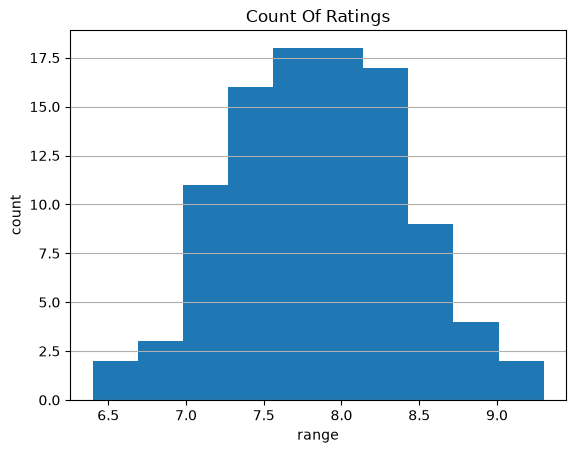

In [6]:
plt.hist(df["Rating"], bins=10, rwidth=10)
plt.xlabel("range")
plt.ylabel("count")
plt.title("Count Of Ratings")
plt.grid(axis="y")
plt.show()

In [7]:
df.isna().sum()

Name           0
Span           0
Description    0
Rating         0
dtype: int64

In [8]:
t = TfidfVectorizer(stop_words="english")

text = df["Name"].str.lower() + " " + df["Description"].str.lower()

text[0]

text_num = t.fit_transform(text)

In [9]:
print(text_num[0])

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 13 stored elements and shape (1, 1015)>
  Coords	Values
  (0, 76)	0.2890384537884246
  (0, 44)	0.21198901201060238
  (0, 777)	0.20032116193578062
  (0, 206)	0.2890384537884246
  (0, 502)	0.3149865982380902
  (0, 78)	0.2890384537884246
  (0, 191)	0.2706279523117682
  (0, 393)	0.2890384537884246
  (0, 143)	0.21198901201060238
  (0, 623)	0.3149865982380902
  (0, 423)	0.2563476579369243
  (0, 735)	0.3149865982380902
  (0, 75)	0.3149865982380902


In [10]:
word = t.get_feature_names_out()

word[76]

'batman'

In [11]:
input_user = input("describe your cartoon").lower()
print(input_user)
input_num = t.transform([input_user])
print(input_num)

a boy in a war
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2 stored elements and shape (1, 1015)>
  Coords	Values
  (0, 99)	0.6553616517132763
  (0, 970)	0.7553152358212074


In [12]:
max_idx = np.argmax(input_num.data)
max_number = input_num.indices[max_idx]
max_word = word[max_number]
print(max_word)

war


In [13]:
similarity = cosine_similarity(text_num, input_num).flatten()

In [14]:
top_3 = np.argsort(similarity)[-3:]

In [15]:
print("<<<=---------------------=>>>")
print("داستان انتخابی شما -->", input_user)
print("کارتون های پیشنهاد شده -->")
print("<<<=---------------------=>>>")
for i in top_3:
    print("اسم کارتون پیشنهادی -->", df["Name"][i])
    print("داستان پیشنهادی -->", df["Description"][i])
    print("-----------------------")

<<<=---------------------=>>>
داستان انتخابی شما --> a boy in a war
کارتون های پیشنهاد شده -->
<<<=---------------------=>>>
اسم کارتون پیشنهادی --> Dexter's Laboratory
داستان پیشنهادی --> The misadventures of a boy genius and his annoying sister.
-----------------------
اسم کارتون پیشنهادی --> The Adventures of Jimmy Neutron, Boy Genius
داستان پیشنهادی --> A young boy, who happens to be a genius, lives in a small town with his family and friends and often gets into crazy adventures with them involving the things he invents.
-----------------------
اسم کارتون پیشنهادی --> Avatar: The Last Airbender
داستان پیشنهادی --> In a war-torn world of elemental magic, a young boy reawakens to undertake a dangerous mystic quest to fulfill his destiny as the Avatar, and bring peace to the world.
-----------------------
